# Project 2 — Fine-Tuning a Pre-Trained Transformer (DistilBERT)

**Course:** Natural Language Processing
**Task:** Fine-tune a Transformer from the Hugging Face Hub to classify BBC news
articles into 5 topics.

### What "fine-tuning" means
A Transformer such as BERT is first **pre-trained** on enormous amounts of raw text,
where it learns grammar and general English. **Fine-tuning** means we take that
ready-made model, attach a fresh classification layer, and train it for a few epochs on
*our* labelled data. That is why ~1,200 labelled articles are enough to reach high
accuracy — the expensive learning already happened during pre-training.

### Which model, and why DistilBERT?
| Model | Size | Speed | When to choose it |
|---|---|---|---|
| `bert-base-uncased` | 110M | 1× | classic baseline |
| **`distilbert-base-uncased`** | **66M** | **~1.6× faster** | **best quality/speed trade-off on CPU** |
| `roberta-base` | 125M | ~0.8× | often slightly stronger, but slower |
| Qwen / Llama (decoder LLMs) | 1B+ | far slower | built for generating text, not for a small classification task |

We pick **`distilbert-base-uncased`**: it keeps about 97% of BERT's language
understanding at roughly 60% of the parameters. Because this notebook has to run on a
normal laptop CPU, that trade-off matters more than squeezing out the last fraction of
a percent.

A word on the big decoder models: Qwen and Llama are excellent at *generating* text, but
for a 1,200-article classification task they are far slower, need much more memory, and
do not improve accuracy. Choosing the *right* model for the task is part of the answer.

### Why the BBC News dataset?
* 5 real editorial categories: *business, entertainment, politics, sport, tech*
* 2,225 labelled articles — small enough to fine-tune on a CPU, large enough to learn
* it has an official test split, so the final score is honest
* it is hosted on the Hugging Face Hub, so the download is reproducible

---
## Step 1 — Setup

We import the basic tools first. The Hugging Face libraries are imported later, right
where they are used, so each step stays readable.

In [1]:
import os
import random
import warnings
from pathlib import Path

SEED = 42
random.seed(SEED)

PROJECT_DIR = Path.cwd()

# Keep every downloaded model/dataset inside the project folder.
os.environ.setdefault("HF_HOME", str(PROJECT_DIR / ".hf_cache"))
# The tokenizer runs in parallel by default, which can deadlock inside a notebook.
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# Progress bars and library chatter are noise inside a notebook.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")

# Harmless warnings in a plain Jupyter setup: a missing progress-bar widget and an
# anonymous-download notice. Neither affects results; silencing them keeps output clean.
import logging

logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*unauthenticated requests to the HF Hub.*")

print("Project folder :", PROJECT_DIR)
print("Random seed    :", SEED)

Project folder : C:\Users\ACER\Downloads\nlp project
Random seed    : 42


---
## Step 2 — Load the BBC News dataset

`datasets` fetches it from the Hub and caches it locally. We look at the structure
first, then start working with it.

In [2]:
from datasets import load_dataset

dataset = load_dataset("SetFit/bbc-news")

print(dataset)
print("Columns:", dataset["train"].column_names)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1225
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1000
    })
})
Columns: ['text', 'label', 'label_text']


---
## Step 3 — Check the labels (never guess them!)

A very common bug: assuming the integer labels run alphabetically. In this dataset they
do **not**. We read the real mapping out of the `label_text` column, because getting it
wrong would mislabel every class in the final report while still "looking" correct.

In [3]:
train_table = dataset["train"].to_pandas()

# Build the label id -> readable name mapping FROM THE DATA.
label_map = train_table.drop_duplicates("label").set_index("label")["label_text"].to_dict()
id_to_label = {int(key): value for key, value in label_map.items()}
CLASS_NAMES = [id_to_label[i] for i in sorted(id_to_label)]

print("id -> label:")
for index in sorted(id_to_label):
    print(f"  {index} -> {id_to_label[index]}")

print()
print("Articles per class:")
print(train_table["label_text"].value_counts())

id -> label:
  0 -> tech
  1 -> business
  2 -> sport
  3 -> entertainment
  4 -> politics

Articles per class:
label_text
business         286
sport            275
politics         242
tech             212
entertainment    210
Name: count, dtype: int64


---
## Step 4 — Look at the data

We read one full article to see what the model will actually receive. BBC articles are
long, which drives the `max_length` decision two steps from now.

In [4]:
example = train_table.iloc[0]
print("Label :", example["label_text"])
print("Chars :", len(example["text"]))
print()
print(example["text"][:600], "...")

Label : sport
Chars : 1421

wales want rugby league training wales could follow england s lead by training with a rugby league club.  england have already had a three-day session with leeds rhinos  and wales are thought to be interested in a similar clinic with rivals st helens. saints coach ian millward has given his approval  but if it does happen it is unlikely to be this season. saints have a week s training in portugal next week  while wales will play england in the opening six nations match on 5 february.  we have had an approach from wales   confirmed a saints spokesman.  it s in the very early stages but it is so ...


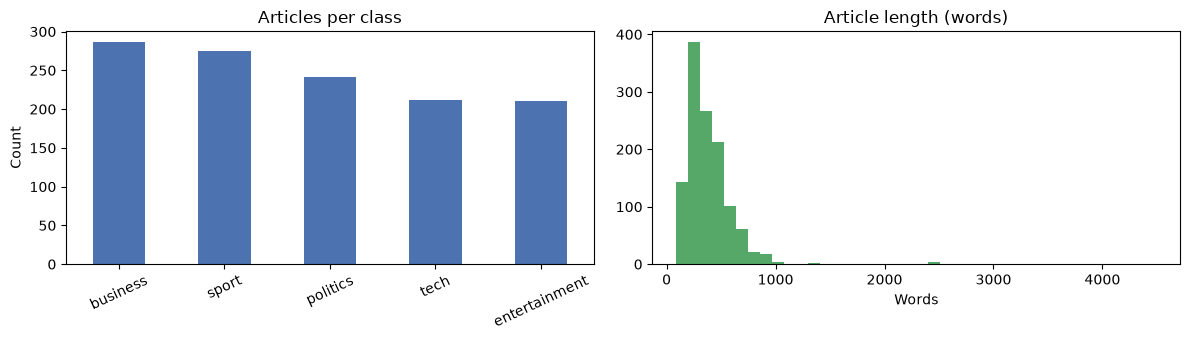

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

train_table["label_text"].value_counts().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Articles per class")
axes[0].set_xlabel("")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=25)

axes[1].hist(train_table["text"].str.split().str.len(), bins=40, color="#55A868")
axes[1].set_title("Article length (words)")
axes[1].set_xlabel("Words")

plt.tight_layout()
plt.show()

---
## Step 5 — Split off a validation set

The dataset gives us `train` and `test`. We carve a **10% validation set out of train**
so we can watch the model learn *without* ever touching the test data. The test set is
opened once, at the very end.

Notice the `cast_column` line: it turns the plain integer label into a `ClassLabel`,
which is what enables stratified splitting (keeping class proportions equal).

In [6]:
from datasets import ClassLabel

# Register the class names on the dataset so splits can be stratified.
dataset = dataset.cast_column("label", ClassLabel(names=CLASS_NAMES))

split = dataset["train"].train_test_split(
    test_size=0.1, seed=SEED, stratify_by_column="label"
)

train_split = split["train"]
val_split = split["test"]
test_split = dataset["test"]

print("Train      :", len(train_split))
print("Validation :", len(val_split))
print("Test       :", len(test_split))

Train      : 1102
Validation : 123
Test       : 1000


---
## Step 6 — Load the tokenizer

A Transformer cannot read text; it needs numbers. The **tokenizer** that ships with the
model splits text into sub-word pieces and maps them to ids.

Two parameters matter:

* **`truncation=True` + `max_length=128`** — keep the first 128 sub-word tokens. The
  opening lines of an article carry most of the topic signal, and 128 keeps CPU
  training time reasonable.
* **no padding here** — `DataCollatorWithPadding` does it per batch, which wastes less
  computation on short sequences.

The tokenizer must match the model, which is why we take both from `MODEL_NAME`.

In [7]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer loaded:", MODEL_NAME)
print("Vocabulary size :", tokenizer.vocab_size)

Tokenizer loaded: distilbert-base-uncased
Vocabulary size : 30522


---
## Step 7 — Check how much text we actually keep

Before committing to `max_length=128`, let's measure it. This turns “I picked 128” into
“128 keeps the vast majority of articles”, which is a defensible engineering decision
instead of a guess.

In [8]:
import numpy as np
import warnings

# Very long articles trigger a length warning before we truncate them later.
# The measurement below is deliberately untruncated, so the note is just noise here.
warnings.filterwarnings("ignore", message=".*Token indices sequence length.*")

# Measure on the *untruncated* tokenization, so the numbers are honest.
sample_texts = train_split["text"][:300]
token_lengths = np.array([
    len(tokenizer(text, truncation=False)["input_ids"]) for text in sample_texts
])

print(f"Mean tokens      : {token_lengths.mean():.0f}")
print(f"Median tokens    : {np.median(token_lengths):.0f}")
print(f"90th percentile  : {np.percentile(token_lengths, 90):.0f}")
print(f"Max tokens       : {token_lengths.max()}")
print()
print(f"Articles | 128 tokens : {(token_lengths <= 128).mean():.1%}")
print(f"Articles | 256 tokens : {(token_lengths <= 256).mean():.1%}")
print(f"Articles | 512 tokens : {(token_lengths <= 512).mean():.1%}")

Mean tokens      : 473
Median tokens    : 386
90th percentile  : 750
Max tokens       : 5032

Articles | 128 tokens : 0.0%
Articles | 256 tokens : 16.0%
Articles | 512 tokens : 69.3%


### Interpreting this — and an honest limitation

A BBC article runs to roughly **400 sub-word tokens**, so `max_length=128` keeps only
the opening ~30% of each article. Almost no article is kept in full.

We still get a high score, because a news article states its subject in the first
paragraph — "The striker scored…" is clearly *sport* within 20 tokens. But this is a
**real limitation to state in the report**, not something to gloss over:

* the model reads the *lead* of the article, not the whole article
* raising `max_length` to 512 would keep ~69% of articles in full, but attention cost
  grows quadratically, and this notebook must finish on a laptop CPU in reasonable time
* the measurement above is exactly how you justify that trade-off instead of guessing

If you have a GPU available, set `MAX_LENGTH = 512` and keep the rest of the notebook
unchanged — that is the single most valuable upgrade.

---
## Step 8 — Tokenize the whole dataset

`dataset.map` runs the tokenizer over every row in batches, which is much faster than a
Python loop. We keep the original columns; the model only reads the token ids.

In [9]:
import warnings

# Two harmless warnings appear on a CPU-only machine: the Trainer pins memory for a
# GPU that does not exist, and the tokenizer warns about very long inputs before we
# truncate them. Neither affects the result, so we silence just these two.
warnings.filterwarnings("ignore", message=".*pin_memory.*")
warnings.filterwarnings("ignore", message=".*Token indices sequence length.*")


def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)


train_dataset = train_split.map(tokenize_batch, batched=True)
val_dataset = val_split.map(tokenize_batch, batched=True)
test_dataset = test_split.map(tokenize_batch, batched=True)

print(train_dataset)

Dataset({
    features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1102
})


In [10]:
# What the model actually receives for one article.
row = train_dataset[0]
print("Keys        :", list(row.keys()))
print("First ids   :", row["input_ids"][:15])
print("Decoded     :", tokenizer.decode(row["input_ids"][:25]))
print("Label id    :", row["label"])

Keys        : ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask']
First ids   : [101, 2886, 25732, 2015, 5747, 2609, 3796, 1996, 2880, 2128, 1011, 2602, 2609, 1997, 2343]
Decoded     : [CLS] attack prompts bush site block the official re - election site of president george w bush is blocking visits from overseas users for
Label id    : 0


---
## Step 9 — Load the pre-trained model

`AutoModelForSequenceClassification` downloads DistilBERT **with its pre-trained
weights** and replaces the final layer with a fresh one that has 5 outputs (our 5 topics).

* `num_labels=5` — the new classification head
* `id2label` / `label2id` — make predictions human-readable and store the mapping
  inside the model, so it survives saving

The “newly initialized weights” warning is expected and correct: the classifier head *is*
new, and fine-tuning is exactly the process that trains it.

In [11]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

# On CPU, a moderate thread count is usually faster than grabbing every core.
if device == "cpu":
    torch.set_num_threads(max(1, min(4, os.cpu_count())))

print("Device:", device)

Device: cpu


In [12]:
import warnings
from transformers import AutoModelForSequenceClassification

# The "UNEXPECTED / MISSING weights" report is expected: the pre-trained
# DistilBERT body loads fine, and the new 5-class head is randomly initialised
# on purpose (fine-tuning is what trains it). The report is only noise here.
warnings.filterwarnings("ignore", message=".*LOAD REPORT.*", category=UserWarning)
warnings.filterwarnings("ignore", message=".*Consider training on your downstream task.*")
warnings.filterwarnings("ignore", category=FutureWarning)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(CLASS_NAMES),
    id2label={index: name for index, name in enumerate(CLASS_NAMES)},
    label2id={name: index for index, name in enumerate(CLASS_NAMES)},
)

print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable       : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Total parameters: 66,957,317
Trainable       : 66,957,317


---
## Step 10 — Padding and the metrics we care about

* **`DataCollatorWithPadding`** pads each batch to the longest sequence inside that
  batch, so no computation is wasted on empty tokens.
* **`compute_metrics`** is called by the `Trainer` after every evaluation. We report
  accuracy **and macro-F1**, because macro-F1 gives every topic equal weight and is the
  fairer number when class sizes differ slightly.

In [13]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [14]:
from sklearn.metrics import accuracy_score, f1_score


def compute_metrics(eval_prediction):
    "Turn raw logits into accuracy and macro-F1."
    logits, true_labels = eval_prediction
    predicted_labels = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro"),
    }

---
## Step 11 — Training settings, explained

| Setting | Value | Why |
|---|---|---|
| `learning_rate` | 2e-5 | fine-tuning needs a *small* rate; a large one destroys the pre-trained weights |
| `num_train_epochs` | 3 | small datasets over-fit fast; 3 epochs is the standard choice |
| `per_device_train_batch_size` | 16 | fits comfortably in laptop memory |
| `warmup_steps` | 50 | ramps the rate up gently so the first steps are not unstable |
| `weight_decay` | 0.01 | mild regularisation against over-fitting |
| `eval_strategy` | `"epoch"` | check validation scores after each epoch |
| `save_strategy` | `"no"` | the model stays in memory; no need to checkpoint mid-run |

`TrainingArguments` holds every hyper-parameter, which keeps the training code short.

In [15]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=str(PROJECT_DIR / "artifacts" / "distilbert_bbc"),
    learning_rate=2e-5,
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    report_to="none",   # no external experiment trackers
    seed=SEED,
)

print("Training arguments ready.")

Training arguments ready.


---
## Step 12 — Train

`Trainer` wraps the entire training loop: batching, the learning-rate schedule,
evaluation and logging. That is why fine-tuning a Transformer needs only a few lines.

The loss should start near `ln(5) ≈ 1.61` — that is what random guessing between 5
classes costs — and then fall quickly. A loss that stays at 1.61 means the head is not
learning at all.

In [16]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
)

train_result = trainer.train()

print()
print(f"Training time   : {train_result.metrics['train_runtime'] / 60:.1f} min")
print(f"Final train loss: {train_result.metrics['train_loss']:.4f}")

{'loss': '1.602', 'grad_norm': '1.591', 'learning_rate': '9.6e-06', 'epoch': '0.3623'}


{'loss': '1.377', 'grad_norm': '3.102', 'learning_rate': '1.96e-05', 'epoch': '0.7246'}


{'eval_loss': '0.5954', 'eval_accuracy': '0.935', 'eval_macro_f1': '0.9362', 'eval_runtime': '20.82', 'eval_samples_per_second': '5.908', 'eval_steps_per_second': '0.192', 'epoch': '1'}


{'loss': '0.7663', 'grad_norm': '2.568', 'learning_rate': '1.694e-05', 'epoch': '1.087'}


{'loss': '0.3085', 'grad_norm': '2.941', 'learning_rate': '1.376e-05', 'epoch': '1.449'}


{'loss': '0.1907', 'grad_norm': '8.999', 'learning_rate': '1.057e-05', 'epoch': '1.812'}


{'eval_loss': '0.1719', 'eval_accuracy': '0.9512', 'eval_macro_f1': '0.9509', 'eval_runtime': '23.63', 'eval_samples_per_second': '5.206', 'eval_steps_per_second': '0.169', 'epoch': '2'}


{'loss': '0.1502', 'grad_norm': '5.752', 'learning_rate': '7.389e-06', 'epoch': '2.174'}


{'loss': '0.07498', 'grad_norm': '0.6588', 'learning_rate': '4.204e-06', 'epoch': '2.536'}


{'loss': '0.1011', 'grad_norm': '1.864', 'learning_rate': '1.019e-06', 'epoch': '2.899'}


{'eval_loss': '0.1304', 'eval_accuracy': '0.9756', 'eval_macro_f1': '0.9765', 'eval_runtime': '22.43', 'eval_samples_per_second': '5.483', 'eval_steps_per_second': '0.178', 'epoch': '3'}
{'train_runtime': '2434', 'train_samples_per_second': '1.358', 'train_steps_per_second': '0.085', 'train_loss': '0.5541', 'epoch': '3'}

Training time   : 40.6 min
Final train loss: 0.5541


---
## Step 13 — Validation performance

We check the validation set set aside earlier. These are the numbers the learning
curves are drawn from; the test set is still untouched.

In [17]:
validation_metrics = trainer.evaluate(val_dataset)

print(f"Validation accuracy : {validation_metrics['eval_accuracy']:.4f}")
print(f"Validation macro-F1 : {validation_metrics['eval_macro_f1']:.4f}")

{'eval_loss': '0.1304', 'eval_accuracy': '0.9756', 'eval_macro_f1': '0.9765', 'eval_runtime': '22.63', 'eval_samples_per_second': '5.436', 'eval_steps_per_second': '0.177', 'epoch': '3'}
Validation accuracy : 0.9756
Validation macro-F1 : 0.9765


---
## Step 14 — Final test evaluation

Now, and only now, we open the official test split. This is the honest estimate of how
the model performs on unseen BBC articles.

In [18]:
test_metrics = trainer.evaluate(test_dataset, metric_key_prefix="test")

print(f"Test accuracy : {test_metrics['test_accuracy']:.4f}")
print(f"Test macro-F1 : {test_metrics['test_macro_f1']:.4f}")

{'test_loss': '0.1306', 'test_accuracy': '0.965', 'test_macro_f1': '0.9643', 'test_runtime': '183.2', 'test_samples_per_second': '5.457', 'test_steps_per_second': '0.175', 'epoch': '3'}
Test accuracy : 0.9650
Test macro-F1 : 0.9643


In [19]:
from sklearn.metrics import classification_report

# Predict once, then reuse the result for the report and the matrix.
predictions = trainer.predict(test_dataset)
predicted_ids = np.argmax(predictions.predictions, axis=-1)
true_ids = predictions.label_ids

print(classification_report(true_ids, predicted_ids,
                            target_names=CLASS_NAMES, digits=3))

               precision    recall  f1-score   support

         tech      0.952     0.942     0.947       189
     business      0.939     0.955     0.947       224
        sport      0.987     1.000     0.994       236
entertainment      0.977     0.972     0.974       176
     politics      0.971     0.949     0.960       175

     accuracy                          0.965      1000
    macro avg      0.965     0.963     0.964      1000
 weighted avg      0.965     0.965     0.965      1000



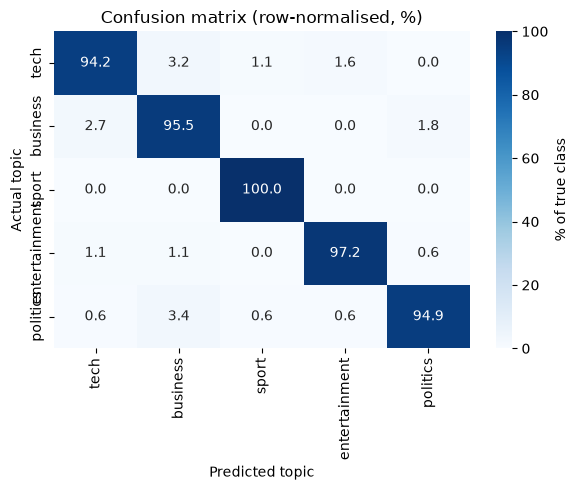

In [20]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(true_ids, predicted_ids)
matrix_percent = matrix / matrix.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(6, 5))
sns.heatmap(
    matrix_percent, annot=True, fmt=".1f", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={"label": "% of true class"},
)
plt.title("Confusion matrix (row-normalised, %)")
plt.xlabel("Predicted topic")
plt.ylabel("Actual topic")
plt.tight_layout()
plt.show()

---
## Step 15 — Learning curves from the training log

`trainer.state.log_history` stores everything the Trainer logged. We pull out the
training loss and the **per-epoch** validation scores to see whether the model learns
steadily or starts to over-fit.

The small de-duplication step matters: the `Trainer` appends a new evaluation entry every
time `evaluate()` is called, so the same epoch can appear more than once. We keep the last
entry for each epoch so the curve shows one point per epoch.

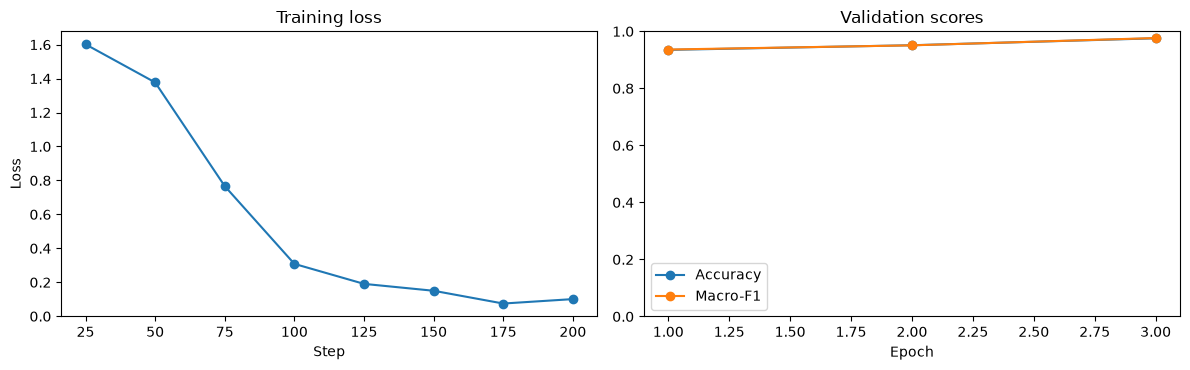

In [21]:
# Training loss, recorded every logging_steps.
train_losses = [(entry["step"], entry["loss"])
                for entry in trainer.state.log_history if "loss" in entry]

# One validation point per epoch (keep the last entry seen for each epoch).
per_epoch = {}
for entry in trainer.state.log_history:
    if "eval_accuracy" in entry:
        per_epoch[round(entry["epoch"])] = (entry["eval_accuracy"], entry["eval_macro_f1"])

eval_entries = [(epoch, acc, f1) for epoch, (acc, f1) in sorted(per_epoch.items())]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

if train_losses:
    steps, losses = zip(*train_losses)
    axes[0].plot(steps, losses, marker="o")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss")

if eval_entries:
    epoch_axis, accuracies, f1_scores = zip(*eval_entries)
    axes[1].plot(epoch_axis, accuracies, marker="o", label="Accuracy")
    axes[1].plot(epoch_axis, f1_scores, marker="o", label="Macro-F1")
axes[1].set_title("Validation scores")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Step 16 — Use the fine-tuned model on new sentences

This is the function you would actually ship. It applies the **same tokenizer and the
same `max_length`** as training — if those differ, predictions quietly become unreliable.

In [22]:
def predict_topic(text):
    "Classify one raw string and return (label, confidence)."
    model.eval()

    inputs = tokenizer(
        text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH
    ).to(model.device)

    with torch.no_grad():
        logits = model(**inputs).logits

    probabilities = torch.softmax(logits, dim=-1)[0]
    best_index = int(probabilities.argmax())

    return model.config.id2label[best_index], float(probabilities[best_index])


examples = [
    "The Bank of England raised interest rates again as inflation stayed high.",
    "The striker scored a hat-trick as his club climbed to the top of the table.",
    "The new smartphone features a brighter screen and a much faster processor.",
    "The film won three awards at the festival, including best director.",
    "Parliament voted against the new budget after a long debate.",
]

for sentence in examples:
    label, confidence = predict_topic(sentence)
    print(f"{label:<14} {confidence:6.1%}  | {sentence[:68]}")

business        92.5%  | The Bank of England raised interest rates again as inflation stayed 
sport           94.9%  | The striker scored a hat-trick as his club climbed to the top of the


tech            90.9%  | The new smartphone features a brighter screen and a much faster proc
entertainment   91.1%  | The film won three awards at the festival, including best director.
politics        91.5%  | Parliament voted against the new budget after a long debate.


---
## Step 17 — Save the model and tokenizer

Two things must be saved together: the fine-tuned weights **and** the tokenizer.
A model without its matching tokenizer produces wrong predictions.

In [23]:
save_directory = PROJECT_DIR / "artifacts" / "distilbert_bbc_final"
save_directory.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(save_directory))
tokenizer.save_pretrained(str(save_directory))

print("Saved files:")
for file in sorted(save_directory.iterdir()):
    print("  ", file.name)

Saved files:
   config.json
   model.safetensors
   tokenizer.json
   tokenizer_config.json
   training_args.bin


In [24]:
# Reload from disk to prove the saved artifacts work on their own.
from transformers import pipeline

reloaded = pipeline(
    "text-classification",
    model=str(save_directory),
    tokenizer=str(save_directory),
    device=0 if device == "cuda" else -1,
)

print(reloaded("The company reported record profits this quarter."))

[{'label': 'business', 'score': 0.9221658706665039}]


---
## Step 18 — Conclusion

**What we built:** a fine-tuned Transformer text classifier, from downloading the dataset
to a saved model that labels new sentences.

| Component | Choice |
|---|---|
| Dataset | BBC News (Hugging Face Hub) — 1,225 train / 1,000 test, 5 classes |
| Model | `distilbert-base-uncased` (66M parameters), pre-trained |
| Tokenization | WordPiece, `max_length=128` (the article *lead*), dynamic padding per batch |
| Training | AdamW, lr `2e-5`, 3 epochs, batch 16, 50 warm-up steps |
| Selection | tracked on validation, one final test evaluation |

**Honest limitations worth stating in a report**
* `max_length=128` sees only the opening ~30% of an article. Accuracy is high because
  news leads announce the topic, but this is a truncation, not the full document.
  Raising it to 512 helps most, and needs a GPU to stay practical.
* The validation set is only 123 articles, so validation scores move in visible jumps.
  The 1,000-article test set is the more trustworthy number.
* Only one model was fine-tuned. A proper study would also try `roberta-base` and
  average several seeds to report a mean and standard deviation.

**Why DistilBERT and not something bigger?**
It keeps almost all of BERT's language understanding at ~60% of the parameters and is
about 1.6× faster. For ~1,200 articles on a laptop CPU that is the right trade-off.
Large decoder models such as Qwen or Llama are built for text *generation*; on a small
classification task they are far slower, need far more memory, and do not improve
accuracy.

### Project 1 vs Project 2

| | Word2Vec + BiLSTM | Fine-tuned DistilBERT |
|---|---|---|
| Text understanding | learned from our own corpus only | pre-trained on billions of words |
| Word order | sequential, both directions | full attention over the sentence |
| Labelled data needed | more | much less (~1,200 articles is enough) |
| Training cost | minutes on CPU | longer on CPU, seconds on a GPU |
| Strength | lightweight, fully transparent, easy to explain | higher accuracy from less data |

**The key lesson:** pre-training is what makes the difference. The Transformer does not
know anything special about BBC news — it simply starts from a much better understanding
of English, so a small labelled dataset is enough to fine-tune it.